# 02 · Baselines — reference models and calibrated logistic regression

**Goal:** set the bar every later model must beat, using the validation protocol fixed on Day 1.

Reproduce:
```
python -m satelliteguard.models.tune        # bounded logistic grid  -> reports/tuning/logreg_grid.csv
python -m satelliteguard.models.train       # CV + threshold + final fit -> reports/metrics.json, models/
python -m satelliteguard.evaluation.plots   # figures -> reports/figures/1x_*.png
```

**Protocol (all numbers here):** train split only (1,594 segments) · 5-fold `StratifiedGroupKFold` on contiguous
episodes × 3 repeats = 15 folds · every transform fit inside the fold · the frozen test split is **not** used.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from satelliteguard import load_config

cfg = load_config()
P, FIG = cfg["paths"], cfg["paths"]["figures"]
M = json.loads(P["metrics"].read_text())["cv"]
show = lambda name: display(Image(filename=str(FIG / f"{name}.png")))

## 1. Results table

In [2]:
rows = {}
for name, m in M.items():
    f, t = m["cv_folds"], m["cv_oof_at_threshold"]
    rows[name] = {
        "track": m["track"],
        "PR-AUC (fold mean ± sd)": f"{f['pr_auc_mean']:.3f} ± {f['pr_auc_std']:.3f}",
        "ROC-AUC": f"{f['roc_auc_mean']:.3f}",
        "threshold": round(t["threshold"], 3),
        "precision": t["precision"], "recall": t["recall"], "F1": t["f1"], "MCC": t["mcc"],
        "recall@top25%": t["recall_at_top25pct"], "Brier": t.get("brier"),
    }
pd.DataFrame(rows).T

,track,PR-AUC (fold mean ± sd),ROC-AUC,threshold,precision,recall,F1,MCC,recall@top25%,Brier
prevalence,reference,0.201 ± 0.002,0.500,0.201,0.2032,0.9844,0.3369,0.0289,0.2866,0.1608
channel_only,reference,0.250 ± 0.050,0.485,0.063,0.2181,1.0,0.3581,0.1446,0.2181,0.1723
logreg,supervised,0.878 ± 0.078,0.945,0.383,0.827,0.8193,0.8232,0.7788,0.891,0.0598
logreg_balanced,supervised,0.873 ± 0.083,0.948,0.464,0.756,0.8879,0.8166,0.7697,0.891,0.0712


- **Reference rows.** `prevalence` gives PR-AUC = anomaly rate (0.20), the floor for any ranking. `channel_only`
  reaches 0.25, and its ROC-AUC under grouped CV is **below 0.5**: a channel's anomaly rate learned on some episodes
  does not transfer to unseen episodes. Channel identity is not a usable shortcut.
- **Logistic regression** reaches **PR-AUC 0.88 ± 0.08**, far above both references. At the review threshold it flags
  ~20% of segments with **precision 0.83 / recall 0.82**.
- The fold standard deviation (≈0.08) is large: the 243 episodes differ a lot, and some folds get hard episodes.
  Differences between models smaller than this should not be over-interpreted.

*Threshold-dependent columns use the policy threshold chosen on these same out-of-fold scores, so they are slightly
optimistic; the frozen test gives the unbiased check.*

## 2. Hyperparameter choice — the one-standard-error rule

In [3]:
grid = pd.read_csv(P["metrics"].parent / "tuning" / "logreg_grid.csv")
grid.pivot(index="C", columns="scaling", values="pr_auc_mean").round(4)

scaling,quantile,standard
C,,
0.01,0.8329,0.7973
0.10,0.8602,0.8397
1.00,0.8785,0.8705
10.00,0.8861,0.8860
100.00,0.8892,0.8856


PR-AUC keeps creeping up as regularisation weakens (best: C = 100), but the gains (≈0.01) are far smaller than
the fold noise. We apply the **one-standard-error rule**: choose the *most regularised* model whose mean score is
within one standard error of the best. This gives **C = 1, quantile scaling** — a simpler model with
statistically indistinguishable performance, which is less likely to have been chosen by noise.

Quantile-normal scaling is used because the raw features are heavy-tailed with magnitudes down to 1e-10; a rank-based
transform makes them comparable without manual log transforms. (It barely matters for the score, as the grid shows.)

## 3. Precision–recall curves

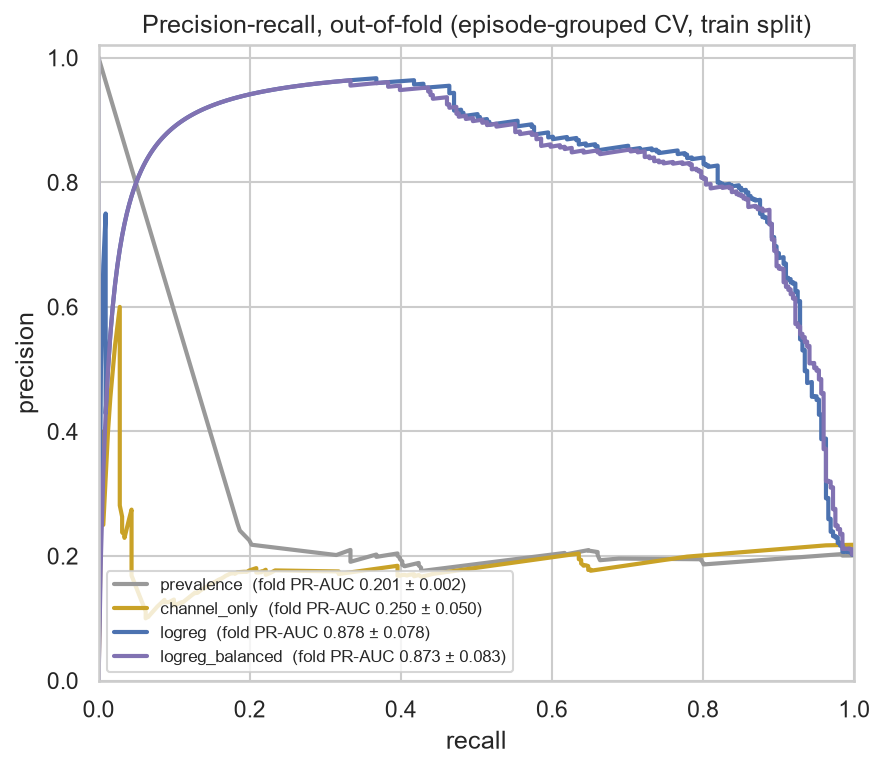

In [4]:
show("10_cv_pr_curves")

## 4. Calibration: why the primary model is *unweighted*

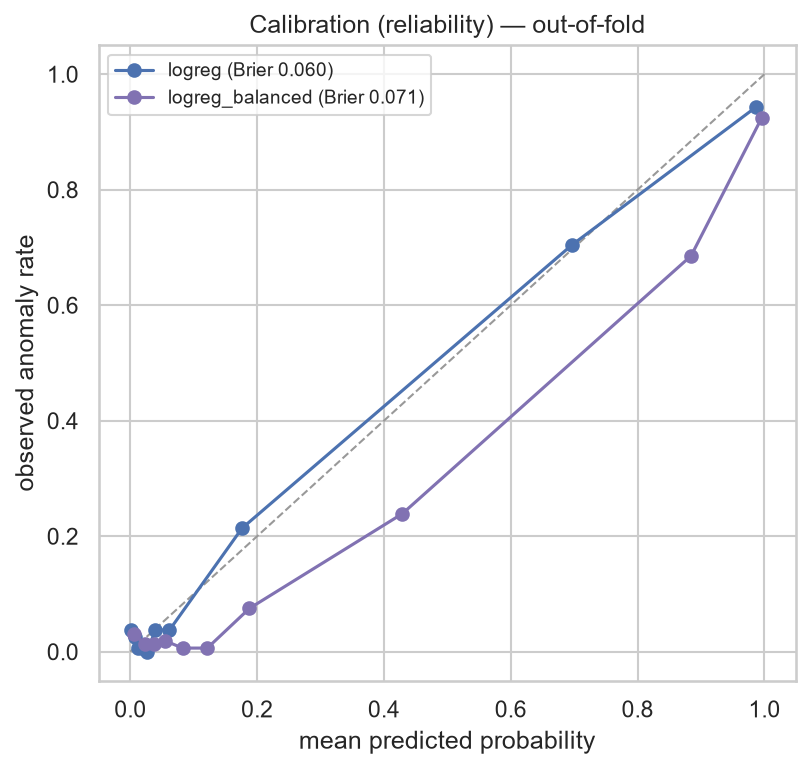

In [5]:
show("11_cv_calibration")

Logistic regression minimises log-loss, so with no re-weighting its probabilities are calibrated by construction
(Brier **0.060**, curve on the diagonal). `class_weight="balanced"` pretends anomalies are as common as normal
segments; its probabilities are inflated (Brier **0.071**, curve below the diagonal) while PR-AUC barely changes.

**Lesson:** re-weighting can shift the decision threshold but it damages probabilities. Since the dashboard shows a
*probability* to operators, we keep the unweighted model and handle imbalance through the **threshold policy**.

## 5. Threshold policy for the review queue

{
  "threshold": 0.3829030518101562,
  "policy": "max F1 s.t. recall >= 0.8",
  "cv_precision": 0.8270440251572327,
  "cv_recall": 0.8193146417445483,
  "cv_f1": 0.8231611893583725
}


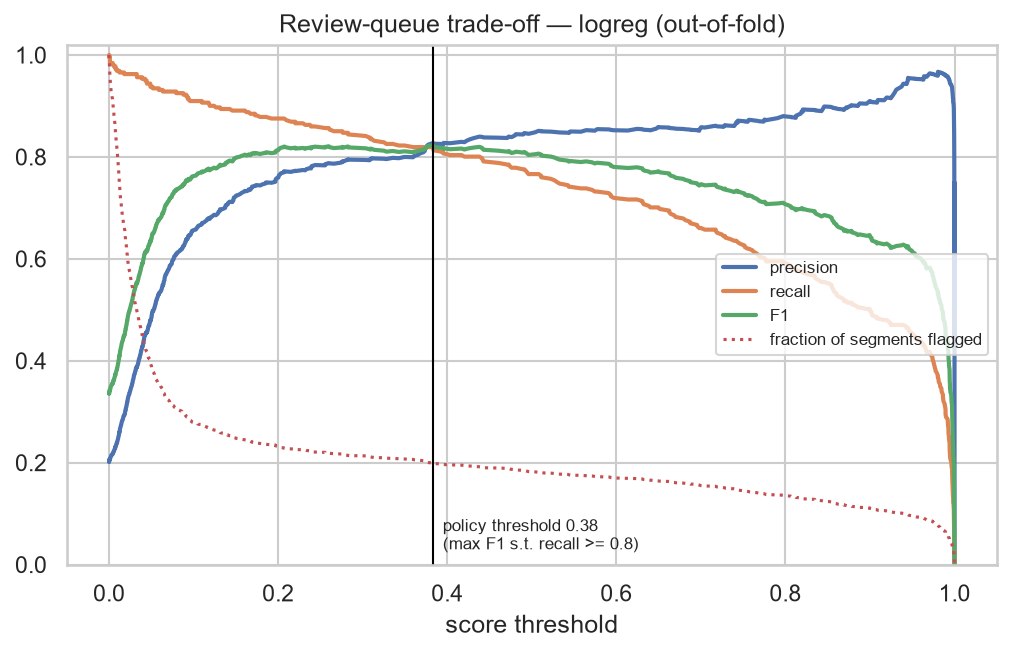

In [6]:
print(json.dumps(M["logreg"]["threshold_policy"], indent=2))
show("12_cv_threshold_tradeoff")

Declared policy: **maximise F1 subject to recall ≥ 0.80** (missing an anomalous segment is assumed costlier than
reviewing a false alarm). It is chosen on out-of-fold training predictions only. The dashboard will let a user move the
threshold and see this trade-off, labelled as a *review-queue policy*, not a safety threshold.

## 6. What does the model use?

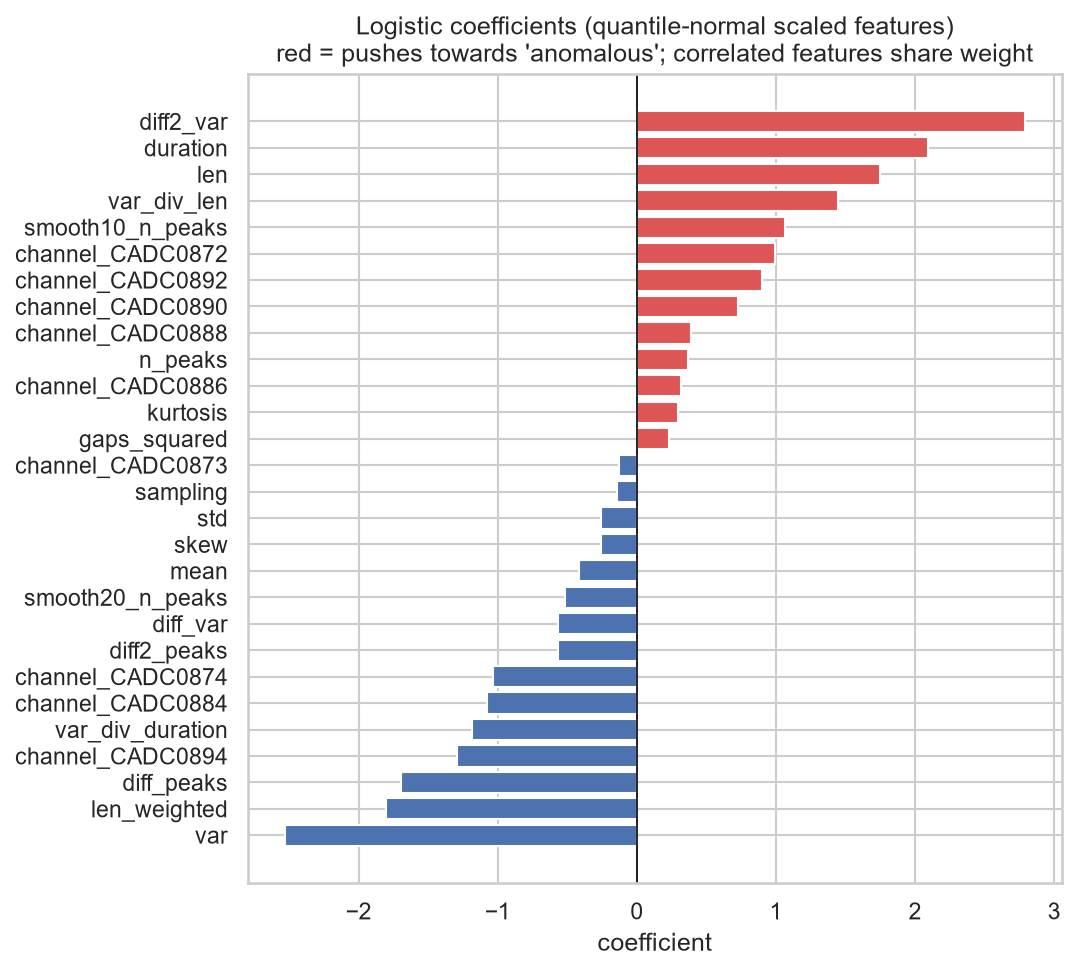

In [7]:
show("13_logreg_coefficients")

Correlated features receive **opposite-sign** weights (`duration` + vs `len_weighted` −; `var` − vs `var_div_len` +).
This is the collinearity flagged in the EDA: the model uses *contrasts* between near-duplicate features, so individual
coefficients are not interpretable as independent effects, and none of this is a causal statement about the spacecraft.
Day 3 uses SHAP on the tree model for per-segment explanations.

## Summary

| | |
|---|---|
| Floor to beat | PR-AUC 0.20 (prevalence), 0.25 (channel only) |
| Baseline | logistic regression, C = 1 (one-SE rule), quantile scaling, unweighted |
| Grouped-CV PR-AUC | **0.878 ± 0.078** |
| Review policy | threshold 0.38 → precision 0.83, recall 0.82, ~20% of segments flagged |
| Calibration | good (Brier 0.060); class weighting makes it worse (0.071) |
| Next | gradient-boosted trees (Day 3): must beat 0.878 by more than the fold noise to justify the extra complexity |